# 02 · Full-year 2024 flight-data audit

Inspect all twelve BTS Reporting Carrier files one month at a time. Raw files remain unchanged. Outputs are descriptive development-data summaries; 2025 is not read.

**Ranking rule:** rank departure airports by the number of reported flight records in 2024, including cancellations, breaking ties alphabetically by airport code. This measures reported scheduled activity, not completed takeoffs or all US aviation. Compare this ranking with non-cancelled flights before accepting the selection. Delay rates use non-cancelled flights with valid labels only.

**Source:** [BTS Reporting Carrier On-Time Performance](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ). Local files were downloaded manually; download dates are unknown. File hashes below identify the exact inputs.

Select the thesis virtual environment in VS Code and **Run All**. Running this notebook refreshes the small audit tables and charts under `outputs/2024_audit/`. It does not create a cleaned training dataset.

In [1]:
from pathlib import Path
import calendar
import hashlib
import json
import platform
import time
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/raw/bts/2024/otr_01_2024.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from the Thesis root or notebooks folder")
DATA = ROOT / "data/raw/bts/2024"
OUT = ROOT / "outputs/2024_audit"
files = [DATA / f"otr_{m:02d}_2024.csv" for m in range(1, 13)]
assert all(p.is_file() for p in files), "One or more monthly files are missing"
unexpected = sorted(p.name for p in DATA.glob("*.csv") if p not in files)
assert not unexpected, f"Review additional CSV files: {unexpected}"
print(f"Python {platform.python_version()}, pandas {pd.__version__}")
print(f"12 files, {sum(p.stat().st_size for p in files)/1e9:.2f} GB")
required = ["FlightDate", "Origin", "OriginAirportID", "Dest", "Reporting_Airline",
            "Flight_Number_Reporting_Airline", "CRSDepTime", "Distance",
            "DepDelay", "DepDel15", "Cancelled", "Diverted"]
key = ["FlightDate", "Reporting_Airline", "Flight_Number_Reporting_Airline",
       "Origin", "Dest", "CRSDepTime"]
monthly_rows, airport_parts, missing_parts, manifests, schema_rows = [], [], [], [], []
baseline_columns = None

Python 3.14.3, pandas 3.0.6
12 files, 3.20 GB


## Monthly coverage, schema, missingness and duplicates

Exact duplicates are checked across all original columns. A second check identifies repeated candidate flight keys (date, reporting airline, flight number, origin, destination, scheduled departure). Repeated keys are flagged for investigation, never automatically deleted. Once dates are verified to belong to disjoint months, exact records and date-containing keys cannot duplicate across monthly files.

For each column, record missing-value counts and inferred types. Inferred type differences can reflect missingness rather than a changed source schema. Empty conditional fields are not automatically errors. Label consistency is checked against `DepDelay >= 15`.

In [2]:
for month, path in enumerate(files, start=1):
    started = time.monotonic()
    df = pd.read_csv(path, low_memory=False,
                     dtype={"CRSDepTime": "string", "CRSArrTime": "string"})
    absent = sorted(set(required) - set(df.columns))
    assert not absent, f"{path.name}: missing required columns {absent}"
    columns = list(df.columns)
    if baseline_columns is None:
        baseline_columns = columns
    schema_rows.append({"month": month, "columns": len(columns),
                        "same_columns_and_order_as_january": columns == baseline_columns,
                        "added": json.dumps(sorted(set(columns)-set(baseline_columns))),
                        "removed": json.dumps(sorted(set(baseline_columns)-set(columns)))})
    dates = pd.to_datetime(df.FlightDate, errors="coerce")
    assert dates.notna().all(), f"{path.name}: invalid dates"
    assert (dates.dt.year.eq(2024) & dates.dt.month.eq(month)).all(), f"{path.name}: wrong month"
    assert dates.dt.day.nunique() == calendar.monthrange(2024, month)[1], f"{path.name}: missing days"
    assert df.Cancelled.isin([0,1]).all(), f"{path.name}: invalid cancellation flags"
    assert df.Diverted.isin([0,1]).all(), f"{path.name}: invalid diversion flags"
    assert df.DepDel15.dropna().isin([0,1]).all(), f"{path.name}: invalid labels"
    cancelled = df.Cancelled.eq(1)
    eligible = ~cancelled & df.DepDel15.notna()
    comparable = df.DepDelay.notna() & df.DepDel15.notna()
    mismatch = int((df.loc[comparable, "DepDel15"] != df.loc[comparable, "DepDelay"].ge(15)).sum())
    exact_duplicates = int(df.duplicated().sum())
    key_duplicates = int(df.duplicated(subset=key).sum())
    monthly_rows.append({"month": month, "reported_flights": len(df),
        "days": dates.dt.day.nunique(), "cancelled": int(cancelled.sum()),
        "missing_labels": int(df.DepDel15.isna().sum()),
        "cancelled_with_label": int((cancelled & df.DepDel15.notna()).sum()),
        "noncancelled_missing_label": int((~cancelled & df.DepDel15.isna()).sum()),
        "diverted": int(df.Diverted.eq(1).sum()),
        "exact_duplicate_excess_rows": exact_duplicates, "key_duplicate_excess_rows": key_duplicates,
        "key_missing_rows": int(df[key].isna().any(axis=1).sum()),
        "label_mismatches": mismatch, "label_without_delay": int((df.DepDel15.notna() & df.DepDelay.isna()).sum()),
        "eligible_flights": int(eligible.sum()),
        "delayed_flights": int(df.loc[eligible, "DepDel15"].sum())})
    small = df[["Origin"]].assign(reported_flights=1, noncancelled_flights=(~cancelled).astype(int),
        eligible_flights=eligible.astype(int), delayed_flights=(eligible & df.DepDel15.eq(1)).astype(int))
    assert small.Origin.notna().all(), f"{path.name}: missing origins"
    airport_parts.append(small.groupby("Origin").sum())
    missing = pd.DataFrame({"month": month, "column": columns,
        "dtype": df.dtypes.astype(str).values, "missing": df.isna().sum().values})
    missing["missing_pct"] = missing["missing"] / len(df) * 100
    missing_parts.append(missing)
    with path.open("rb") as stream:
        digest = hashlib.file_digest(stream, "sha256").hexdigest()
    manifests.append({"file": str(path.relative_to(ROOT)), "bytes": path.stat().st_size,
                      "sha256": digest, "rows": len(df)})
    print(f"Month {month:02d}: {len(df):,} rows; {exact_duplicates} exact duplicates; "
          f"{key_duplicates} repeated-key excess rows; {time.monotonic()-started:.1f}s", flush=True)
    del df, small

monthly = pd.DataFrame(monthly_rows).set_index("month")
monthly["delay_rate"] = monthly.delayed_flights / monthly.eligible_flights
monthly["cancellation_rate"] = monthly.cancelled / monthly.reported_flights
schema = pd.DataFrame(schema_rows)
missingness = pd.concat(missing_parts, ignore_index=True)
display(monthly)
display(schema)
print("Annual totals:")
display(monthly.drop(columns=["delay_rate", "cancellation_rate"]).sum().to_frame("Total"))
print(f"Annual eligible-flight delay rate: {monthly.delayed_flights.sum()/monthly.eligible_flights.sum():.2%}")

Month 01: 547,271 rows; 0 exact duplicates; 0 repeated-key excess rows; 6.7s


Month 02: 519,221 rows; 0 exact duplicates; 0 repeated-key excess rows; 6.3s


Month 03: 591,767 rows; 0 exact duplicates; 0 repeated-key excess rows; 7.3s


Month 04: 582,185 rows; 0 exact duplicates; 0 repeated-key excess rows; 8.9s


Month 05: 609,743 rows; 0 exact duplicates; 0 repeated-key excess rows; 9.7s


Month 06: 611,132 rows; 0 exact duplicates; 0 repeated-key excess rows; 8.3s


... (7 outputs left out)

,month,columns,same_columns_and_order_as_january,added,removed
0,1,110,True,[],[]
1,2,110,True,[],[]
2,3,110,True,[],[]
3,4,110,True,[],[]
4,5,110,True,[],[]
5,6,110,True,[],[]
6,7,110,True,[],[]
7,8,110,True,[],[]
8,9,110,True,[],[]
9,10,110,True,[],[]


Annual totals:


,Total
reported_flights,7079061
days,366
cancelled,96315
missing_labels,92970
cancelled_with_label,3345
noncancelled_missing_label,0
diverted,17499
exact_duplicate_excess_rows,0
key_duplicate_excess_rows,0
key_missing_rows,1


Annual eligible-flight delay rate: 20.64%


## Annual airport ranking and sensitivity check

Rates below pool eligible flights within each airport. They are descriptive rates, not evaluation metrics or equal-airport averages. Show the top fifteen to make the selection boundary visible. If duplicate or schema issues exist, treat rankings as provisional until investigated.

In [3]:
airports = pd.concat(airport_parts).groupby(level=0).sum().reset_index()
airports = airports.sort_values(["reported_flights", "Origin"], ascending=[False, True]).reset_index(drop=True)
airports.insert(0, "reported_rank", range(1, len(airports)+1))
alternative = airports.sort_values(["noncancelled_flights", "Origin"], ascending=[False, True]).copy()
alternative["noncancelled_rank"] = range(1, len(alternative)+1)
airports = airports.merge(alternative[["Origin", "noncancelled_rank"]], on="Origin", validate="one_to_one")
airports["delay_rate"] = airports.delayed_flights / airports.eligible_flights
airports["selected"] = airports.reported_rank.le(10)
assert airports.reported_flights.sum() == monthly.reported_flights.sum()
assert airports.eligible_flights.sum() == monthly.eligible_flights.sum()
assert airports.delayed_flights.sum() == monthly.delayed_flights.sum()
display(airports.head(15).round({"delay_rate": 4}))
selected = airports.loc[airports.selected, "Origin"].tolist()
alternative_set = set(alternative.head(10).Origin)
print("Selected by reported activity:", ", ".join(selected))
print("Same top-ten membership using non-cancelled flights:", set(selected) == alternative_set)
print("Membership difference:", sorted(set(selected) ^ alternative_set))
print(f"Selected airports cover {airports.loc[airports.selected, 'reported_flights'].sum()/airports.reported_flights.sum():.1%} of reported records")
critical = monthly[["exact_duplicate_excess_rows", "key_duplicate_excess_rows", "key_missing_rows", "label_mismatches"]].sum()
print("Issues requiring review:", critical.to_dict())
print("Identical column layouts:", bool(schema.same_columns_and_order_as_january.all()))

,reported_rank,Origin,reported_flights,noncancelled_flights,eligible_flights,delayed_flights,noncancelled_rank,delay_rate,selected
0,1,ATL,341910,338500,338500,66820,1,0.1974,True
1,2,DFW,313582,307745,307745,84623,2,0.2750,True
2,3,DEN,308645,305160,305160,70715,3,0.2317,True
3,4,ORD,280052,276267,276267,61205,4,0.2215,True
4,5,CLT,217555,214578,214578,56724,5,0.2644,True
5,6,LAX,194053,192472,192472,34704,6,0.1803,True
6,7,PHX,193551,192373,192373,38617,7,0.2007,True
7,8,LAS,189252,187582,187582,44155,8,0.2354,True
8,9,SEA,163724,161911,161911,33269,9,0.2055,True
9,10,LGA,162432,158586,158586,28489,10,0.1796,True


Selected by reported activity: ATL, DFW, DEN, ORD, CLT, LAX, PHX, LAS, SEA, LGA
Same top-ten membership using non-cancelled flights: True
Membership difference: []
Selected airports cover 33.4% of reported records
Issues requiring review: {'exact_duplicate_excess_rows': 0, 'key_duplicate_excess_rows': 0, 'key_missing_rows': 1, 'label_mismatches': 0}
Identical column layouts: True


## Visual overview

These charts describe variation across the observed months and airports. They do not establish causes or multi-year seasonality.

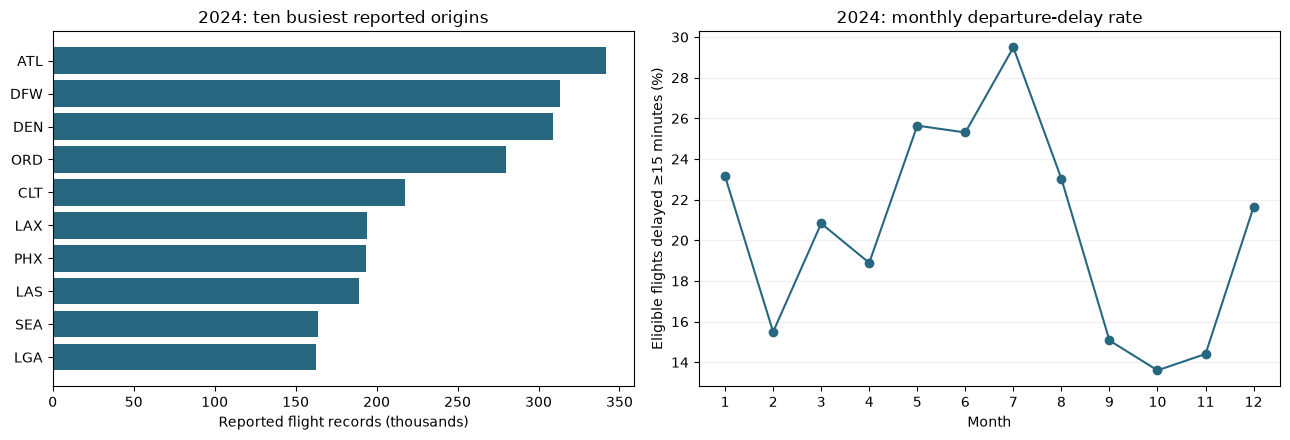

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
top = airports.head(10).iloc[::-1]
axes[0].barh(top.Origin, top.reported_flights / 1000, color="#286780")
axes[0].set(title="2024: ten busiest reported origins", xlabel="Reported flight records (thousands)")
axes[1].plot(monthly.index, monthly.delay_rate * 100, marker="o", color="#286780")
axes[1].set(title="2024: monthly departure-delay rate", xlabel="Month", ylabel="Eligible flights delayed ≥15 minutes (%)", xticks=range(1,13))
axes[1].grid(axis="y", alpha=.2)
fig.tight_layout()
plt.show()

## Save reproducible audit summaries

Only summaries and input provenance are exported. Keep raw data in its original location. The JSON stores the ranking rule and selected airport codes so later preprocessing can reuse the same selection. Review the checks above before using this selection for modelling.

Next: agree on predictor columns available two hours before departure, build the selected-airport dataset, and match NOAA observations with correct airport timezones. Fit preprocessing and models using source-airport training data only; keep target-airport departures and 2025 out of model selection.

In [5]:
OUT.mkdir(parents=True, exist_ok=True)
monthly.to_csv(OUT / "monthly_audit.csv")
schema.to_csv(OUT / "schema_audit.csv", index=False)
missingness.to_csv(OUT / "column_missingness.csv", index=False)
airports.to_csv(OUT / "airport_ranking.csv", index=False)
pd.DataFrame(manifests).to_csv(OUT / "input_manifest.csv", index=False)
fig.savefig(OUT / "annual_overview.png", dpi=160, bbox_inches="tight")
selection = {"year": 2024, "rule": "Reported flight records by origin, including cancellations; ties by airport code",
             "airports": selected, "same_membership_without_cancellations": set(selected)==alternative_set,
             "review_counts": {k: int(v) for k,v in critical.items()},
             "schema_consistent": bool(schema.same_columns_and_order_as_january.all())}
(OUT / "airport_selection.json").write_text(json.dumps(selection, indent=2) + "\n")
print("Saved audit summaries to", OUT.relative_to(ROOT))

Saved audit summaries to outputs/2024_audit


## Findings from the first complete run

- All 366 days are represented, and all twelve files have the same column layout.
- 7,079,061 reported records; 96,315 cancellations; 6,982,746 eligible non-cancelled flights. Every non-cancelled flight has a delay label.
- No exact duplicates, repeated candidate flight keys, or disagreements between the delay label and the 15-minute threshold.
- One August flight number is missing: 25 August 2024, F9, MIA to ATL, scheduled 06:00, non-cancelled, departure delay -6 minutes. This was checked directly in the August source. Preserve the missing value and flag it; do not invent a flight number. Its origin MIA is outside the selected ten, so it will not enter the selected-origin dataset. This remains an audit finding, not a repaired value.
- Selected origins: ATL, DFW, DEN, ORD, CLT, LAX, PHX, LAS, SEA, LGA. Top-ten membership is unchanged when cancellations are excluded from ranking. These are the busiest origins within this reporting dataset, not a claim about all US airport operations.
- The annual eligible-flight delay rate is 20.64%. Monthly rates range from 13.60% in October to 29.49% in July.

These notes describe the current input files recorded in the manifest. Revisit them if the inputs change.